# 02 Baseline: frozen ResNet50 features + logistic regression

**Idea.** An ImageNet-pretrained ResNet50 already turns an image into a useful 2048-number summary
(the vector right before its final layer). If we freeze the network and only train a linear classifier
(logistic regression) on top of those vectors, we learn how far "generic ImageNet features" get us without
changing the network at all. This is called *feature extraction* or a *linear probe*.

It is the lower bound for the fine-tuning runs in the 2x2 table: if fine-tuning is not clearly better than
this, the extra training cost is not worth it.

Runs: full image and bbox crop. Train on the train split, choose the regularization strength `C` on val.
The test split is not touched.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import config as C
from dataset import CarDataset, make_loader, seed_everything
from evaluate import metrics_from_probs, save_predictions
from models import build_feature_extractor

seed_everything()
device = C.get_device()
FIG_DIR = ROOT / "docs" / "figures"
print(device)

cuda


## 1. Extract features
Images go through the same eval preprocessing as the fine-tuned models (resize to 224 x 224, no
augmentation), so the only difference between baseline and fine-tuning is whether the backbone learns.

In [2]:
@torch.no_grad()
def extract(split, crop):
    ds = CarDataset(split, crop=crop, train=False)
    model = build_feature_extractor().to(device)
    feats, labels = [], []
    for x, y in make_loader(ds, 128, shuffle=False, num_workers=4):
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=device.type == "cuda"):
            feats.append(model(x.to(device)).float().cpu())
        labels.append(y)
    return torch.cat(feats).numpy(), torch.cat(labels).numpy(), ds.df

features = {}
for crop in (False, True):
    name = "baseline_crop" if crop else "baseline_full"
    out = C.OUTPUTS_DIR / name
    out.mkdir(parents=True, exist_ok=True)
    for split in ("train", "val"):
        f = out / f"features_{split}.npy"
        if not f.exists():
            t = time.time()
            X, y, _ = extract(split, crop)
            np.save(f, X); np.save(out / f"labels_{split}.npy", y)
            print(f"{name} {split}: {X.shape} in {time.time() - t:.0f}s")
        features[(name, split)] = (np.load(f), np.load(out / f"labels_{split}.npy"))

## 2. Logistic regression, choose C on val

`C` is the inverse of regularization strength: small `C` keeps weights small (simpler model), large `C`
lets the model fit the training data more closely. With 2048 features and only about 35 images per class,
overfitting is a real risk, so we try a range on a log scale and pick the best on val. Features are
standardized first (zero mean, unit variance per feature, fit on train only) so one `C` means the same
thing for every feature.

In [3]:
C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
results, best = [], {}
for name in ("baseline_full", "baseline_crop"):
    Xtr, ytr = features[(name, "train")]
    Xva, yva = features[(name, "val")]
    scaler = StandardScaler().fit(Xtr)
    Xtr_s, Xva_s = scaler.transform(Xtr), scaler.transform(Xva)
    for c in C_GRID:
        t = time.time()
        clf = LogisticRegression(C=c, max_iter=2000, random_state=C.SEED).fit(Xtr_s, ytr)
        probs = clf.predict_proba(Xva_s)
        m = metrics_from_probs(probs, yva)
        train_acc = clf.score(Xtr_s, ytr)
        results.append({"run": name, "C": c, "train_top1": train_acc, **{f"val_{k}": v for k, v in m.items()}})
        print(f"{name} C={c:<6} train {train_acc:.3f}  val top1 {m['top1']:.4f}  ({time.time() - t:.0f}s)")
        if m["top1"] > best.get(name, (None, -1))[1]:
            best[name] = (c, m["top1"], probs, m)

sweep = pd.DataFrame(results)
sweep.to_csv(C.OUTPUTS_DIR / "baseline_c_sweep.csv", index=False)

baseline_full C=0.001  train 0.881  val top1 0.3363  (8s)


baseline_full C=0.003  train 0.985  val top1 0.3985  (7s)


baseline_full C=0.01   train 0.999  val top1 0.4198  (8s)


baseline_full C=0.03   train 0.999  val top1 0.4214  (19s)


baseline_full C=0.1    train 0.999  val top1 0.4272  (5s)


baseline_full C=0.3    train 0.999  val top1 0.4223  (6s)


... (4 outputs left out)

baseline_crop C=0.03   train 0.999  val top1 0.4910  (34s)


baseline_crop C=0.1    train 0.999  val top1 0.4926  (34s)


baseline_crop C=0.3    train 0.999  val top1 0.4935  (32s)


baseline_crop C=1.0    train 0.999  val top1 0.4918  (46s)


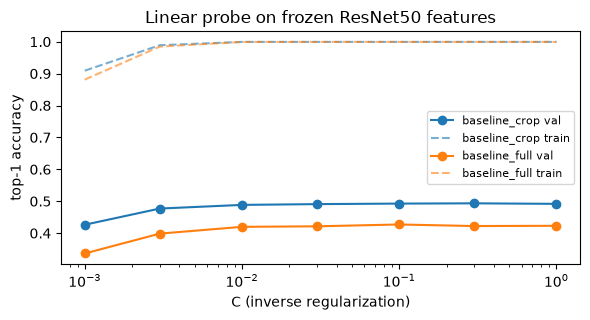

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.3))
for name, g in sweep.groupby("run"):
    l, = ax.plot(g.C, g.val_top1, "o-", label=f"{name} val")
    ax.plot(g.C, g.train_top1, "--", color=l.get_color(), alpha=0.6, label=f"{name} train")
ax.set(xscale="log", xlabel="C (inverse regularization)", ylabel="top-1 accuracy",
       title="Linear probe on frozen ResNet50 features")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "baseline_c_sweep.png")

## 3. Save the chosen baseline runs
Same files as the fine-tuning runs (config, metrics, predictions), so the 2x2 table reads every run the
same way.

In [5]:
val_df = pd.read_csv(C.SPLITS_DIR / "val.csv")
for name, (c, top1, probs, m) in best.items():
    out = C.OUTPUTS_DIR / name
    cfg = {"run_name": name, "crop": name.endswith("crop"), "method": "frozen ResNet50 + logistic regression",
           "weights": "IMAGENET1K_V2", "img_size": C.IMG_SIZE, "bbox_margin": C.BBOX_MARGIN,
           "standardize": True, "C": c, "C_grid": C_GRID, "seed": C.SEED}
    (out / "config.json").write_text(json.dumps(cfg, indent=2))
    (out / "metrics_val.json").write_text(json.dumps(m | {"C": c}, indent=2))
    save_predictions(val_df, probs, out / "predictions_val.csv")
    np.save(out / "probs_val.npy", probs.astype(np.float16))
    print(f"{name}: best C={c}, val top-1 {m['top1']:.4f}, top-5 {m['top5']:.4f}, "
          f"mean per-class {m['mean_per_class_acc']:.4f}")

baseline_full: best C=0.1, val top-1 0.4272, top-5 0.7046, mean per-class 0.4241
baseline_crop: best C=0.3, val top-1 0.4935, top-5 0.7766, mean per-class 0.4921


## What we learn

See the printed numbers above. Two things to look at:

1. **Crop vs full.** If the crop wins here too, the gain comes from the input itself (more pixels on the
   car, less background), not from anything fine-tuning does.
2. **Train vs val gap.** Training accuracy near 100% with much lower val accuracy means the linear head is
   memorizing. ImageNet features describe "this is a car" well, but they were never trained to separate a
   2007 from a 2012 Audi S4. Fine-tuning lets the backbone learn those fine details, which is what the next
   runs test.